# Phase 2 — Receiver-impairment shift (shift B, E2)

Frozen source models (Phase 1 DroneDetect linear tail, Phase 0 DroneRF `recording_dedup`) scored on impaired
versions of their own test rows. Impairments: `rfml_uav.data.impairments` (4 kinds × severities 1–3, 4 = escalation).
Impaired features: `results/paper3/phase2/{dronedetect,dronerf}/{kind}_{s}.npz` (`X`, `row` = clean-file index).

In [1]:
import os
import itertools
import warnings
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from dotenv import load_dotenv
from imblearn.under_sampling import RandomUnderSampler
from joblib import Parallel, delayed
from scipy.special import logsumexp, softmax
from sklearn.metrics import f1_score, roc_auc_score
from tqdm import tqdm

from rfml_uav.data.impairments import SEVERITY, KIND_ID, impair
from rfml_uav.data.wavelets import iq_wpd_features, wpd_features
from rfml_uav.drone_detect.dataset import DRONES, inventory, read
from rfml_uav.drone_rf.utils import get_class_label
from rfml_uav.eval.metrics import classification_report_dict
from rfml_uav.eval.splits import make_splits
from rfml_uav.eval.stats import paired_test
from rfml_uav.nn.models import get_model
from rfml_uav.nn.train import predict_logits

load_dotenv()
DATA = os.getenv("DATA_PATH")
out = os.path.join(DATA, "results/paper3/phase2")
for d in ("dronedetect/parts", "dronerf/parts", "runs"):
    os.makedirs(os.path.join(out, d), exist_ok=True)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

SEED, WINDOW, N_JOBS = 0, 4000, 12
SEEDS, K_FOLDS = [0, 1, 2, 3, 4], 5
CELLS = [(k, s) for k in SEVERITY for s in (1, 2, 3)]
OFFSET_CELLS = [("gainoffset", s) for s in (1, 2, 3)]  # constant gain only (no step): gain-invariance check
DD_CLASSES, RF_CLASSES = list(DRONES), ["Background", "Bebop", "AR", "Phantom"]

In [2]:
def apply_cell(w, cell, row_id):
    """Impair one window for cell (kind, severity); every draw depends only on (SEED, kind, severity, row_id)."""
    kind, s = cell
    k = "gain" if kind == "gainoffset" else kind
    return impair(w, k, s, np.random.default_rng([SEED, KIND_ID[k], s, row_id]), step=kind != "gainoffset")


def name(cell):
    return f"{cell[0]}_{cell[1]}"


def missing(dataset, cells):
    return [c for c in cells if not os.path.exists(os.path.join(out, dataset, name(c) + ".npz"))]


def save_atomic(path, **arrays):
    np.savez(path + ".tmp.npz", **arrays)
    os.replace(path + ".tmp.npz", path)


def build(dataset, groups, part_fn, cells):
    """groups: [(key, rows, ...)] one task per recording; part_fn(group, cells) -> {cell name: X}.
    Per-recording parts (resume after an interruption), then one row-aligned file per cell."""
    cells = missing(dataset, cells)
    if not cells:
        return
    tag = "-".join(name(c) for c in cells)

    def task(g):
        warnings.filterwarnings("ignore")  # pywt: level 6 is deep for 4000 samples (same as the clean features)
        p = os.path.join(out, dataset, "parts", f"{g[0]}__{tag}.npz")
        if not os.path.exists(p):
            save_atomic(p, **part_fn(g, cells))

    Parallel(n_jobs=N_JOBS)(delayed(task)(g) for g in tqdm(groups, desc=dataset))
    rows = np.concatenate([g[1] for g in groups])
    order = np.argsort(rows, kind="stable")
    for c in cells:
        X = np.concatenate([np.load(os.path.join(out, dataset, "parts", f"{g[0]}__{tag}.npz"))[name(c)] for g in groups])
        save_atomic(os.path.join(out, dataset, name(c) + ".npz"), X=X[order], row=rows[order])
    for g in groups:
        os.remove(os.path.join(out, dataset, "parts", f"{g[0]}__{tag}.npz"))


def load_cell(dataset, cell):
    d = np.load(os.path.join(out, dataset, name(cell) + ".npz"))
    return d["X"], d["row"]

## DroneDetect: every CLEAN active window

In [3]:
F = dict(np.load(os.path.join(DATA, "results/paper3/phase1/features.npz")))
F["y"] = np.array([DD_CLASSES.index(d) for d in F["drone"]])
inv = inventory(os.getenv("DRONEDETECT_PATH")).set_index("rec_id")
DD_ROWS = np.flatnonzero((F["subset"] == "CLEAN") & F["active"])
dd_groups = [(r, DD_ROWS[F["rec_id"][DD_ROWS] == r], inv.loc[r, "path"]) for r in np.unique(F["rec_id"][DD_ROWS])]


def dd_windows(path, rows):
    x = read(path)
    return [np.asarray(x[s:s + WINDOW]) for s in F["start"][rows]]


def dd_part(g, cells):
    _, rows, path = g
    W = dd_windows(path, rows)  # one read per recording (external drive) for all cells
    return {name(c): np.stack([iq_wpd_features(apply_cell(w, c, r)) for w, r in zip(W, rows)]) for c in cells}


print(len(DD_ROWS), "rows,", len(dd_groups), "recordings")
build("dronedetect", dd_groups, dd_part, CELLS)

95000 rows, 95 recordings


In [4]:
# checks: row alignment, identity at severity 0, independence from worker count
rng = np.random.default_rng(0)
for c in CELLS:
    X, row = load_cell("dronedetect", c)
    assert np.array_equal(row, DD_ROWS) and X.shape == (len(DD_ROWS), 256) and not np.isnan(X).any()

sample = np.sort(rng.choice(DD_ROWS, 200, replace=False))
for r_id in np.unique(F["rec_id"][sample]):
    rows = sample[F["rec_id"][sample] == r_id]
    X0 = np.stack([iq_wpd_features(apply_cell(w, ("awgn", 0), r)) for w, r in zip(dd_windows(inv.loc[r_id, "path"], rows), rows)])
    assert np.allclose(X0, F["X"][rows], rtol=1e-5, atol=1e-6), r_id

for g in dd_groups[:2]:  # in-process (n_jobs=1) recomputation equals the parallel result
    part = dd_part(g, CELLS)
    for c in CELLS:
        X, row = load_cell("dronedetect", c)
        assert np.array_equal(part[name(c)], X[np.searchsorted(row, g[1])]), (g[0], c)
print("DroneDetect impaired sets OK")

DroneDetect impaired sets OK


## DroneRF: every non-duplicate window (L and H impaired independently)

In [5]:
W = dict(np.load(os.path.join(DATA, "Wavelets/features.npz")))
W["y"] = np.array([get_class_label(b) for b in W["bui"]])
W["group"] = np.char.add(np.char.add(W["bui"].astype(str), "_"), W["n"].astype(str))
RF_ROWS = np.flatnonzero(~W["is_dup"])
rf_groups = [(gname, RF_ROWS[W["group"][RF_ROWS] == gname]) for gname in np.unique(W["group"][RF_ROWS])]


def rf_windows(gname, rows):
    bui, n = gname.split("_")
    ci = W["chunk_idx"][rows]
    return [np.load(os.path.join(DATA, "chunked", f"{bui}{ch}_{n}.npz"))["arr_0"][ci] for ch in "LH"]


def rf_features(L, H, cell, r):
    return np.array(wpd_features(apply_cell(L, cell, 2 * r)) + wpd_features(apply_cell(H, cell, 2 * r + 1)), dtype=np.float32)


def rf_part(g, cells):
    gname, rows = g
    L, H = rf_windows(gname, rows)
    return {name(c): np.stack([rf_features(l, h, c, r) for l, h, r in zip(L, H, rows)]) for c in cells}


print(len(RF_ROWS), "rows,", len(rf_groups), "recordings")
build("dronerf", rf_groups, rf_part, CELLS + OFFSET_CELLS)

164264 rows, 227 recordings


In [6]:
for c in CELLS + OFFSET_CELLS:
    X, row = load_cell("dronerf", c)
    assert np.array_equal(row, RF_ROWS) and X.shape == (len(RF_ROWS), 256) and not np.isnan(X).any()
sample = np.sort(rng.choice(RF_ROWS, 200, replace=False))
for gname in np.unique(W["group"][sample]):
    rows = sample[W["group"][sample] == gname]
    L, H = rf_windows(gname, rows)
    X0 = np.stack([rf_features(l, h, ("awgn", 0), r) for l, h, r in zip(L, H, rows)])
    assert np.allclose(X0, W["X"][rows], rtol=1e-5, atol=1e-6), gname
print("DroneRF impaired sets OK")

DroneRF impaired sets OK


## Gain invariance

A constant gain offset (no in-window step) must leave the unit-power DroneDetect features unchanged.
DroneRF features are not normalised; their offset-only sets (`gainoffset_{s}`) are scored below.

In [7]:
sample = np.sort(rng.choice(DD_ROWS, 1000, replace=False))
for r_id in np.unique(F["rec_id"][sample]):
    rows = sample[F["rec_id"][sample] == r_id]
    for w, r in zip(dd_windows(inv.loc[r_id, "path"], rows), rows):
        for c in OFFSET_CELLS:
            assert np.allclose(iq_wpd_features(apply_cell(w, c, r)), F["X"][r], rtol=1e-4, atol=1e-6)
print("DroneDetect features are invariant to a constant gain offset (1000 rows, 3, 6, 12 dB)")

DroneDetect features are invariant to a constant gain offset (1000 rows, 3, 6, 12 dB)


## Source-only scoring (no retraining)

In [8]:
def rf_build_dataset(seed):
    """Phase 0 build_dataset(dedup=True, seed), copied verbatim (notebook 0 is frozen)."""
    idx = np.flatnonzero(~W["is_dup"])
    rus = RandomUnderSampler(sampling_strategy="not minority", random_state=seed)
    rus.fit_resample(idx.reshape(-1, 1), W["y"][idx])
    return np.sort(idx[rus.sample_indices_])


def test_rows(dataset, seed, fold):
    if dataset == "dronedetect":
        return np.load(os.path.join(DATA, f"results/paper3/phase1/runs/active_linear_s{seed}_f{fold}.npz"))["test_idx"]
    idx = rf_build_dataset(seed)
    te = idx[make_splits(W["y"][idx], W["group"][idx], "recording", n_folds=K_FOLDS, seed=seed)[fold][2]]
    ref = np.load(os.path.join(DATA, f"results/paper3/phase0/recording_dedup_s{seed}_f{fold}.npz"))
    assert np.array_equal(W["y"][te], ref["y_true"]) and np.array_equal(W["group"][te], ref["test_groups"])
    return te


def load_model(dataset, seed, fold):
    if dataset == "dronedetect":
        model, ckpt = get_model("CNN", input_dim=256, n_classes=7, linear_tail=True), f"phase1/active_linear_s{seed}_f{fold}.pt"
    else:
        model, ckpt = get_model("CNN", input_dim=256, n_classes=4), f"phase0/recording_dedup_s{seed}_f{fold}.pt"
    model.load_state_dict(torch.load(os.path.join(DATA, "checkpoints/paper3", ckpt), map_location=device))
    return model.to(device)


def logits(model, X):
    return predict_logits(model, torch.tensor(X, dtype=torch.float32, device=device).unsqueeze(1)).cpu().numpy()


def score(dataset, cells):
    """Add logits for `cells` (plus clean) to phase2/runs/{dataset}_s{seed}_f{fold}.npz."""
    clean_X = F["X"] if dataset == "dronedetect" else W["X"]
    cell_X = {name(c): load_cell(dataset, c) for c in cells}
    for seed, fold in tqdm(list(itertools.product(SEEDS, range(K_FOLDS))), desc=dataset):
        path = os.path.join(out, "runs", f"{dataset}_s{seed}_f{fold}.npz")
        run = dict(np.load(path)) if os.path.exists(path) else {}
        todo = [n for n in ["clean"] + list(cell_X) if n not in run]
        if not todo:
            continue
        te = run.get("test_idx", None)
        te = test_rows(dataset, seed, fold) if te is None else te
        model = load_model(dataset, seed, fold)
        run["test_idx"] = te
        for n in todo:
            X = clean_X[te] if n == "clean" else cell_X[n][0][np.searchsorted(cell_X[n][1], te)]
            run[n] = logits(model, X)
        save_atomic(path, **run)


score("dronedetect", CELLS)
score("dronerf", CELLS + OFFSET_CELLS)

dronedetect:   0%|          | 0/25 [00:00<?, ?it/s]

dronedetect: 100%|██████████| 25/25 [00:00<00:00, 423.30it/s]

dronerf:   0%|          | 0/25 [00:00<?, ?it/s]

dronerf: 100%|██████████| 25/25 [00:00<00:00, 710.25it/s]

In [9]:
# clean reference reproduced: same macro-F1 as the stored Phase 0 / Phase 1 test predictions
from sklearn.metrics import f1_score
for seed, fold in itertools.product(SEEDS, range(K_FOLDS)):
    dd = np.load(os.path.join(out, "runs", f"dronedetect_s{seed}_f{fold}.npz"))
    ref = np.load(os.path.join(DATA, f"results/paper3/phase1/runs/active_linear_s{seed}_f{fold}.npz"))
    y = F["y"][dd["test_idx"]]
    assert abs(f1_score(y, dd["clean"].argmax(1), average="macro") - f1_score(y, ref["test_logits"].argmax(1), average="macro")) < 1e-6
    rf = np.load(os.path.join(out, "runs", f"dronerf_s{seed}_f{fold}.npz"))
    ref = np.load(os.path.join(DATA, f"results/paper3/phase0/recording_dedup_s{seed}_f{fold}.npz"))
    assert abs(f1_score(ref["y_true"], rf["clean"].argmax(1), average="macro") - f1_score(ref["y_true"], ref["y_pred"], average="macro")) < 1e-6
print("clean macro-F1 reproduced for all 50 runs")

clean macro-F1 reproduced for all 50 runs


## Shift-B table

In [10]:
def auroc(correct, score):
    return roc_auc_score(correct, score) if 0 < correct.mean() < 1 else np.nan


def pm(df, cols, by):
    g = df.groupby(by, sort=False)[cols].agg(["mean", "std"])
    return pd.DataFrame({c: g[(c, "mean")].map("{:.4f}".format) + " ± " + g[(c, "std")].map("{:.4f}".format) for c in cols})


def run_rows():
    rows = []
    for dataset, y_all, classes in [("dronedetect", F["y"], DD_CLASSES), ("dronerf", W["y"], RF_CLASSES)]:
        for seed, fold in itertools.product(SEEDS, range(K_FOLDS)):
            run = np.load(os.path.join(out, "runs", f"{dataset}_s{seed}_f{fold}.npz"))
            y = y_all[run["test_idx"]]
            for n in [k for k in run.files if k != "test_idx"]:
                z = run[n]
                rep = classification_report_dict(y, z.argmax(1), softmax(z, 1), classes)
                correct = z.argmax(1) == y
                kind, s = ("clean", 0) if n == "clean" else (n.rsplit("_", 1)[0], int(n.rsplit("_", 1)[1]))
                rows.append({"dataset": dataset, "kind": kind, "severity": s, "seed": seed, "fold": fold,
                             "escalation": s == 4, **{k: v for k, v in rep.items() if np.isscalar(v)},
                             "energy_auroc": auroc(correct, logsumexp(z, 1)), "msp_auroc": auroc(correct, softmax(z, 1).max(1))})
    return pd.DataFrame(rows)


def tables(runs):
    keys = ["dataset", "kind", "severity"]
    stats = []
    for (dataset, kind, s), g in runs[runs.kind != "clean"].groupby(keys):
        clean = runs[(runs.dataset == dataset) & (runs.kind == "clean")].set_index(["seed", "fold"])["macro_f1"]
        cur = g.set_index(["seed", "fold"])["macro_f1"].reindex(clean.index)
        t = paired_test(clean, cur)
        stats.append({"dataset": dataset, "kind": kind, "severity": s, "macro_f1_drop": t["diff"],
                      "ci_low": t["ci_lo"], "ci_high": t["ci_hi"], "wilcoxon_p": t["p"]})
    stats = pd.DataFrame(stats).set_index(keys)
    order = runs[keys + ["escalation"]].drop_duplicates().set_index(keys)
    table = order.join(pm(runs, ["accuracy", "macro_f1"], keys)).join(stats)
    table.to_csv(os.path.join(out, "shift_b_table.csv"))
    f1_cols = [c for c in runs.columns if c.endswith("_f1") and c != "macro_f1"]
    runs.groupby(keys, sort=False)[f1_cols].mean().round(4).to_csv(os.path.join(out, "shift_b_per_class.csv"))
    dd = runs[runs.dataset == "dronedetect"]
    pm(dd, ["energy_auroc", "msp_auroc"], ["kind", "severity"]).to_csv(os.path.join(out, "shift_b_auroc.csv"))
    return table, stats


runs = run_rows()
table, stats = tables(runs)
for dataset in ("dronedetect", "dronerf"):
    assert len(table.loc[dataset].drop("gainoffset", level="kind", errors="ignore")) >= 13
table

escalation         accuracy         macro_f1  \
dataset     kind       severity                                                 
dronedetect clean      0              False  0.7310 ± 0.0463  0.7274 ± 0.0479   
            awgn       1              False  0.6729 ± 0.0398  0.6653 ± 0.0454   
                       2              False  0.5568 ± 0.0476  0.5424 ± 0.0559   
                       3              False  0.4319 ± 0.0554  0.4092 ± 0.0601   
            gain       1              False  0.7225 ± 0.0468  0.7201 ± 0.0473   
                       2              False  0.7074 ± 0.0494  0.7057 ± 0.0489   
                       3              False  0.6717 ± 0.0549  0.6720 ± 0.0544   
            tilt       1              False  0.7280 ± 0.0454  0.7246 ± 0.0466   
                       2              False  0.7221 ± 0.0432  0.7186 ± 0.0441   
                       3              False  0.7035 ± 0.0392  0.6994 ± 0.0410   
            adc        1              False  0.7296 ± 0.0462  0.7261 ± 0.0478   
                       2              False  0.7257 ± 0.0459  0.7223 ± 0.0472   
                       3              False  0.6915 ± 0.0447  0.6867 ± 0.0478   
            tilt       4               True  0.6621 ± 0.0349  0.6585 ± 0.0393   
dronerf     clean      0              False  0.9651 ± 0.0062  0.9650 ± 0.0064   
            awgn       1              False  0.9624 ± 0.0073  0.9623 ± 0.0075   
                       2              False  0.9437 ± 0.0162  0.9432 ± 0.0167   
                       3              False  0.8904 ± 0.0378  0.8856 ± 0.0428   
            gain       1              False  0.9223 ± 0.0222  0.9225 ± 0.0213   
                       2              False  0.7692 ± 0.0287  0.7777 ± 0.0254   
                       3              False  0.5557 ± 0.0249  0.5673 ± 0.0239   
            tilt       1              False  0.9642 ± 0.0064  0.9641 ± 0.0067   
                       2              False  0.9615 ± 0.0078  0.9614 ± 0.0082   
                       3              False  0.9516 ± 0.0124  0.9514 ± 0.0131   
            adc        1              False  0.9650 ± 0.0062  0.9649 ± 0.0064   
                       2              False  0.9648 ± 0.0063  0.9647 ± 0.0065   
                       3              False  0.9623 ± 0.0067  0.9622 ± 0.0069   
            gainoffset 1              False  0.9369 ± 0.0241  0.9365 ± 0.0245   
                       2              False  0.8291 ± 0.0520  0.8309 ± 0.0491   
                       3              False  0.4807 ± 0.0393  0.5009 ± 0.0424   
            tilt       4               True  0.9193 ± 0.0255  0.9194 ± 0.0256   

                                 macro_f1_drop    ci_low   ci_high  \
dataset     kind       severity                                      
dronedetect clean      0                   NaN       NaN       NaN   
            awgn       1              0.062154  0.045481  0.078055   
                       2              0.185087  0.160642  0.208057   
                       3              0.318296  0.287917  0.347805   
            gain       1              0.007320  0.004120  0.010663   
                       2              0.021785  0.015221  0.028713   
                       3              0.055438  0.045603  0.065746   
            tilt       1              0.002887  0.001026  0.005014   
                       2              0.008830  0.003181  0.014828   
                       3              0.028047  0.018275  0.037823   
            adc        1              0.001311  0.000736  0.001956   
                       2              0.005188  0.002665  0.008128   
                       3              0.040765  0.029484  0.052753   
            tilt       4              0.068995  0.055159  0.082885   
dronerf     clean      0                   NaN       NaN       NaN   
            awgn       1              0.002682  0.001548  0.003760   
                       2              0.021733  0.016653  0.026549   
                       3     

## Escalation (design D9)

Kinds whose DroneDetect severity-3 drop is below 3 pp get severity 4 on both datasets.

In [11]:
s3 = stats.loc["dronedetect"].xs(3, level="severity")["macro_f1_drop"]
ESCALATE = sorted(s3[(s3 < 0.03) & s3.index.isin(list(SEVERITY))].index)
print("severity-3 drops (DroneDetect):", s3.round(4).to_dict(), "→ escalate:", ESCALATE)
if ESCALATE:
    esc = [(k, 4) for k in ESCALATE]
    build("dronedetect", dd_groups, dd_part, esc)
    build("dronerf", rf_groups, rf_part, esc)
    score("dronedetect", esc)
    score("dronerf", esc)
    runs = run_rows()
    table, stats = tables(runs)
sev4 = set(runs[runs.severity == 4].kind)
assert sev4 == set(ESCALATE), (sev4, ESCALATE)
table[["escalation", "accuracy", "macro_f1", "macro_f1_drop", "ci_low", "ci_high", "wilcoxon_p"]]

severity-3 drops (DroneDetect): {'adc': 0.0408, 'awgn': 0.3183, 'gain': 0.0554, 'tilt': 0.028} → escalate: ['tilt']


dronedetect:   0%|          | 0/25 [00:00<?, ?it/s]

dronedetect: 100%|██████████| 25/25 [00:00<00:00, 466.96it/s]

dronerf:   0%|          | 0/25 [00:00<?, ?it/s]

dronerf: 100%|██████████| 25/25 [00:00<00:00, 731.19it/s]

escalation         accuracy         macro_f1  \
dataset     kind       severity                                                 
dronedetect clean      0              False  0.7310 ± 0.0463  0.7274 ± 0.0479   
            awgn       1              False  0.6729 ± 0.0398  0.6653 ± 0.0454   
                       2              False  0.5568 ± 0.0476  0.5424 ± 0.0559   
                       3              False  0.4319 ± 0.0554  0.4092 ± 0.0601   
            gain       1              False  0.7225 ± 0.0468  0.7201 ± 0.0473   
                       2              False  0.7074 ± 0.0494  0.7057 ± 0.0489   
                       3              False  0.6717 ± 0.0549  0.6720 ± 0.0544   
            tilt       1              False  0.7280 ± 0.0454  0.7246 ± 0.0466   
                       2              False  0.7221 ± 0.0432  0.7186 ± 0.0441   
                       3              False  0.7035 ± 0.0392  0.6994 ± 0.0410   
            adc        1              False  0.7296 ± 0.0462  0.7261 ± 0.0478   
                       2              False  0.7257 ± 0.0459  0.7223 ± 0.0472   
                       3              False  0.6915 ± 0.0447  0.6867 ± 0.0478   
            tilt       4               True  0.6621 ± 0.0349  0.6585 ± 0.0393   
dronerf     clean      0              False  0.9651 ± 0.0062  0.9650 ± 0.0064   
            awgn       1              False  0.9624 ± 0.0073  0.9623 ± 0.0075   
                       2              False  0.9437 ± 0.0162  0.9432 ± 0.0167   
                       3              False  0.8904 ± 0.0378  0.8856 ± 0.0428   
            gain       1              False  0.9223 ± 0.0222  0.9225 ± 0.0213   
                       2              False  0.7692 ± 0.0287  0.7777 ± 0.0254   
                       3              False  0.5557 ± 0.0249  0.5673 ± 0.0239   
            tilt       1              False  0.9642 ± 0.0064  0.9641 ± 0.0067   
                       2              False  0.9615 ± 0.0078  0.9614 ± 0.0082   
                       3              False  0.9516 ± 0.0124  0.9514 ± 0.0131   
            adc        1              False  0.9650 ± 0.0062  0.9649 ± 0.0064   
                       2              False  0.9648 ± 0.0063  0.9647 ± 0.0065   
                       3              False  0.9623 ± 0.0067  0.9622 ± 0.0069   
            gainoffset 1              False  0.9369 ± 0.0241  0.9365 ± 0.0245   
                       2              False  0.8291 ± 0.0520  0.8309 ± 0.0491   
                       3              False  0.4807 ± 0.0393  0.5009 ± 0.0424   
            tilt       4               True  0.9193 ± 0.0255  0.9194 ± 0.0256   

                                 macro_f1_drop    ci_low   ci_high  \
dataset     kind       severity                                      
dronedetect clean      0                   NaN       NaN       NaN   
            awgn       1              0.062154  0.045481  0.078055   
                       2              0.185087  0.160642  0.208057   
                       3              0.318296  0.287917  0.347805   
            gain       1              0.007320  0.004120  0.010663   
                       2              0.021785  0.015221  0.028713   
                       3              0.055438  0.045603  0.065746   
            tilt       1              0.002887  0.001026  0.005014   
                       2              0.008830  0.003181  0.014828   
                       3              0.028047  0.018275  0.037823   
            adc        1              0.001311  0.000736  0.001956   
                       2              0.005188  0.002665  0.008128   
                       3              0.040765  0.029484  0.052753   
            tilt       4              0.068995  0.055159  0.082885   
dronerf     clean      0                   NaN       NaN       NaN   
            awgn       1              0.002682  0.001548  0.003760   
                       2              0.021733  0.016653  0.026549   
                       3     

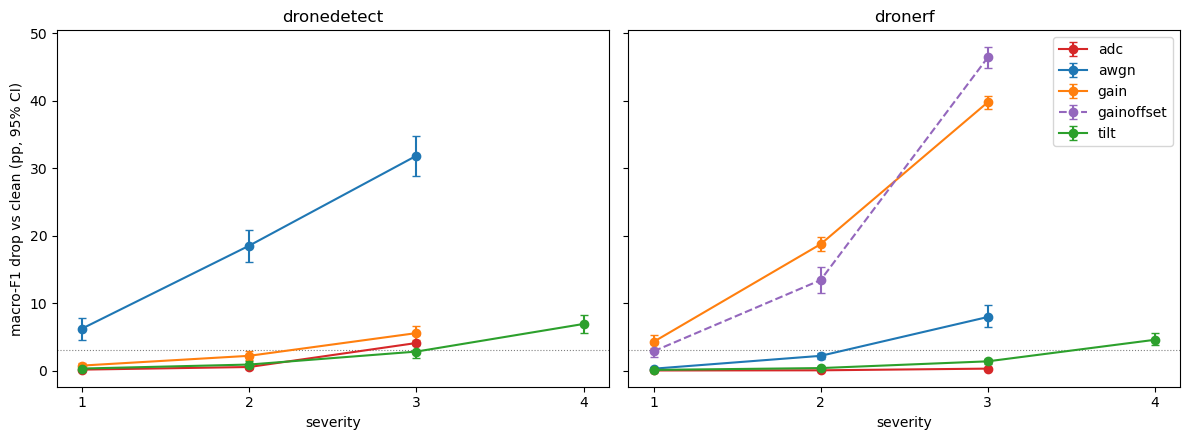

In [12]:
COLORS = dict(zip(list(SEVERITY) + ["gainoffset"], plt.rcParams["axes.prop_cycle"].by_key()["color"]))
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
for ax, dataset in zip(axes, ("dronedetect", "dronerf")):
    st = stats.loc[dataset].reset_index()
    for kind, g in st.groupby("kind"):
        g = g.sort_values("severity")
        ax.errorbar(g.severity, 100 * g.macro_f1_drop, yerr=100 * np.array([g.macro_f1_drop - g.ci_low, g.ci_high - g.macro_f1_drop]),
                    marker="o", capsize=3, label=kind, color=COLORS[kind], linestyle="--" if kind == "gainoffset" else "-")
    ax.axhline(3, color="grey", lw=0.8, ls=":")
    ax.set_title(dataset); ax.set_xlabel("severity"); ax.set_xticks([1, 2, 3, 4])
axes[0].set_ylabel("macro-F1 drop vs clean (pp, 95% CI)"); axes[1].legend()
plt.tight_layout(); fig.savefig(os.path.join(out, "shift_b_drop.png"), dpi=120, bbox_inches="tight"); plt.show()

## Energy-score separability and gain invariance

In [13]:
auroc_table = pd.read_csv(os.path.join(out, "shift_b_auroc.csv"), index_col=[0, 1])
assert auroc_table.notna().all().all()
gi = stats.loc["dronerf"].xs("gainoffset", level="kind")[["macro_f1_drop", "ci_low", "ci_high", "wilcoxon_p"]]
gi.insert(0, "offset_db", [SEVERITY["gain"][s] for s in gi.index])
gi.to_csv(os.path.join(out, "gain_invariance.csv"))
print("DroneDetect: features invariant to a constant gain offset (checked above). DroneRF offset-only drop:")
display(gi)
auroc_table

DroneDetect: features invariant to a constant gain offset (checked above). DroneRF offset-only drop:


,offset_db,macro_f1_drop,ci_low,ci_high,wilcoxon_p
severity,,,,,
1,3,0.028446,0.019514,0.039442,5.960464e-08
2,6,0.134072,0.114811,0.154147,5.960464e-08
3,12,0.464041,0.448093,0.480208,5.960464e-08


energy_auroc        msp_auroc
kind  severity                                  
clean 0         0.8753 ± 0.0290  0.8820 ± 0.0297
awgn  1         0.8610 ± 0.0245  0.8641 ± 0.0270
      2         0.7713 ± 0.0426  0.7672 ± 0.0403
      3         0.7121 ± 0.0641  0.6995 ± 0.0641
gain  1         0.8693 ± 0.0321  0.8771 ± 0.0328
      2         0.8541 ± 0.0340  0.8647 ± 0.0357
      3         0.8399 ± 0.0303  0.8482 ± 0.0328
tilt  1         0.8761 ± 0.0287  0.8822 ± 0.0289
      2         0.8753 ± 0.0276  0.8809 ± 0.0264
      3         0.8683 ± 0.0255  0.8732 ± 0.0244
adc   1         0.8746 ± 0.0292  0.8810 ± 0.0299
      2         0.8735 ± 0.0278  0.8786 ± 0.0287
      3         0.8584 ± 0.0259  0.8592 ± 0.0259
tilt  4         0.8460 ± 0.0191  0.8495 ± 0.0208

## Receiver shortcut under AWGN

Phase 1 in-band models (`active_inband_linear`, WPD nodes <= 14 MHz, 120-d) scored on the same impaired sets.
If AWGN mostly fills the quiet out-of-band nodes the full-band model reads, the in-band drop is smaller.

In [14]:
# in-band WPD columns (notebook 3): [channel I|Q][node 0-29][rms, std]
INBAND = np.array([ch * 128 + node * 2 + st for ch in range(2) for node in range(30) for st in range(2)])
DD_CELLS = [(k, s) for k, s in CELLS] + [(k, 4) for k in ESCALATE]
dd_X = {name(c): load_cell("dronedetect", c) for c in DD_CELLS}
f1s = []
for seed, fold in itertools.product(SEEDS, range(K_FOLDS)):
    te = np.load(os.path.join(DATA, f"results/paper3/phase1/runs/active_inband_linear_s{seed}_f{fold}.npz"))["test_idx"]
    model = get_model("CNN", input_dim=len(INBAND), n_classes=7, linear_tail=True)
    model.load_state_dict(torch.load(os.path.join(DATA, f"checkpoints/paper3/phase1/active_inband_linear_s{seed}_f{fold}.pt"), map_location=device))
    model.to(device)
    f1 = lambda X: f1_score(F["y"][te], logits(model, X[:, INBAND]).argmax(1), average="macro")
    f1s.append({"seed": seed, "fold": fold, "clean": f1(F["X"][te]),
                **{n: f1(X[np.searchsorted(row, te)]) for n, (X, row) in dd_X.items()}})
inb = pd.DataFrame(f1s).set_index(["seed", "fold"])
full = runs[runs.dataset == "dronedetect"].assign(cell=lambda d: d.kind + "_" + d.severity.astype(str))
full = full.pivot_table(index=["seed", "fold"], columns="cell", values="macro_f1").rename(columns={"clean_0": "clean"})
sc = []
for n in dd_X:
    d_full, d_in = full["clean"] - full[n], inb["clean"] - inb[n]
    t = paired_test(d_full, d_in)
    sc.append({"cell": n, "fullband_drop": d_full.mean(), "inband_drop": d_in.mean(), "full_minus_inband": t["diff"],
               "ci_low": t["ci_lo"], "ci_high": t["ci_hi"], "wilcoxon_p": t["p"]})
sc = pd.DataFrame(sc).set_index("cell")

# relative feature shift per WPD node (|impaired - clean| / clean), in-band nodes 0-29 vs out-of-band 30-63
pick = rng.choice(len(DD_ROWS), 20_000, replace=False)
Xc = F["X"][DD_ROWS[pick]]
for k, s in [("awgn", 1), ("awgn", 2), ("awgn", 3)]:
    rel = (np.abs(dd_X[f"{k}_{s}"][0][pick] - Xc).mean(0) / Xc.mean(0)).reshape(2, 64, 2).mean((0, 2))
    sc.loc[f"{k}_{s}", ["rel_shift_inband", "rel_shift_outband"]] = rel[:30].mean(), rel[30:].mean()
sc.to_csv(os.path.join(out, "shortcut_inband.csv"))
print("in-band clean macro-F1:", round(inb["clean"].mean(), 4))
sc.round(4)

in-band clean macro-F1: 0.7015


,fullband_drop,inband_drop,full_minus_inband,ci_low,ci_high,wilcoxon_p,rel_shift_inband,rel_shift_outband
cell,,,,,,,,
awgn_1,0.0622,0.0164,0.0458,0.0290,0.0623,0.0000,0.0414,0.3450
awgn_2,0.1851,0.1014,0.0837,0.0623,0.1024,0.0000,0.1719,1.4039
awgn_3,0.3183,0.1865,0.1318,0.1001,0.1606,0.0000,0.3351,2.5042
gain_1,0.0073,0.0493,-0.0420,-0.0521,-0.0326,0.0000,NaN,NaN
gain_2,0.0218,0.0877,-0.0659,-0.0769,-0.0548,0.0000,NaN,NaN
gain_3,0.0554,0.1233,-0.0678,-0.0839,-0.0514,0.0000,NaN,NaN
tilt_1,0.0029,0.0015,0.0014,-0.0006,0.0037,0.5602,NaN,NaN
tilt_2,0.0088,0.0059,0.0030,-0.0027,0.0091,0.5077,NaN,NaN
tilt_3,0.0280,0.0205,0.0075,-0.0028,0.0180,0.1730,NaN,NaN
